# Multimodal fusion: predicting ICU mortality from vitals, labs and notes

In this tutorial I predict in-hospital mortality for MIMIC-III ICU patients using only what is known
in the **first 24 hours** of their ICU stay. There are two kinds of data for that window:

* **structured data**: vitals from `CHARTEVENTS` and labs from `LABEVENTS`
* **unstructured data**: nursing, physician and radiology notes from `NOTEEVENTS`

I build a model for each one separately and then try three ways of combining them (early, late and
intermediate fusion) to see if the notes add anything on top of the numbers.

**To rebuild this:** you need MIMIC-III v1.4 access. Point `DATA_DIR` in the next cell at the folder
with the `.csv.gz` files. Everything else is standard (pandas, scikit-learn, PyTorch, transformers).
The CHARTEVENTS step takes about 15 minutes and the ClinicalBERT step needs a GPU (a Colab T4 is
fine). Big intermediate results get cached in `cache/` so re-running is quick.

In [1]:
# !pip install transformers scikit-learn pandas pyarrow   # only needed outside Colab
import re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve

warnings.filterwarnings("ignore")

# change this to wherever your MIMIC-III files are
DATA_DIR = Path("../mimic-iii-clinical-database-1.4/mimic-iii-clinical-database-1.4")
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight"})
COLORS = {"structured": "#0173B2", "notes": "#DE8F05", "fusion": "#029E73"}

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png")
    plt.show()

print("torch", torch.__version__, "| device:", DEVICE)

torch 2.14.0+cu130 | device: cuda


## 1. Cohort

I start from `ICUSTAYS` and add age, gender and the outcome (`HOSPITAL_EXPIRE_FLAG`) from `PATIENTS`
and `ADMISSIONS`. The rules:

1. first ICU stay per patient (so the same person can't end up in both train and test)
2. adults only (18+)
3. ICU stay of at least 24 hours, since that is my observation window
4. still alive at hour 24 (otherwise we'd be "predicting" something that already happened)
5. at least one note written in the first 24 hours (needed for the notes model)

In [2]:
icu = pd.read_csv(DATA_DIR / "ICUSTAYS.csv.gz", parse_dates=["INTIME", "OUTTIME"])
pat = pd.read_csv(DATA_DIR / "PATIENTS.csv.gz", parse_dates=["DOB"])
adm = pd.read_csv(DATA_DIR / "ADMISSIONS.csv.gz", parse_dates=["DEATHTIME"])

df = (icu.merge(pat[["SUBJECT_ID", "GENDER", "DOB"]], on="SUBJECT_ID")
         .merge(adm[["HADM_ID", "ADMISSION_TYPE", "DEATHTIME", "HOSPITAL_EXPIRE_FLAG"]], on="HADM_ID"))
# MIMIC shifts ages over 89 to ~300, so I cap them at 90
df["AGE"] = (df["INTIME"].dt.year - df["DOB"].dt.year).clip(upper=90)

funnel = [("all ICU stays", len(df))]
df = df.sort_values("INTIME").groupby("SUBJECT_ID").head(1);      funnel.append(("first stay per patient", len(df)))
df = df[df["AGE"] >= 18];                                        funnel.append(("age 18+", len(df)))
df = df[df["LOS"] >= 1];                                         funnel.append(("ICU stay >= 24h", len(df)))
died_early = (df["DEATHTIME"] - df["INTIME"]) < pd.Timedelta(hours=24)
df = df[~died_early];                                            funnel.append(("alive at hour 24", len(df)))
print(pd.DataFrame(funnel, columns=["step", "ICU stays"]).to_string(index=False))

                  step  ICU stays
         all ICU stays      61532
first stay per patient      46476
               age 18+      38538
       ICU stay >= 24h      32575
      alive at hour 24      32418


## 2. Notes from the first 24 hours

`NOTEEVENTS` is about 4 GB unzipped, so I read it in chunks and only keep notes that

* belong to a cohort admission,
* have a `CHARTTIME` between ICU admission and hour 24, and
* aren't marked as errors.

Discharge summaries only have a date, not a time, so the `CHARTTIME` filter drops them
automatically. That matters a lot, because a discharge summary basically tells you the outcome.
I also strip the de-identification placeholders like `[**2150-3-1**]`. I never print any note text,
only counts, because of the MIMIC data use agreement.

In [3]:
DEID = re.compile(r"\[\*\*.*?\*\*\]")

def clean(text):
    text = DEID.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()

notes_path = CACHE / "notes_24h.parquet"
if notes_path.exists():
    notes = pd.read_parquet(notes_path)
else:
    t0 = time.time()
    intime = df.set_index("HADM_ID")["INTIME"]
    keep = []
    for ch in pd.read_csv(DATA_DIR / "NOTEEVENTS.csv.gz", chunksize=200_000, dtype={"HADM_ID": "Int64"},
                          usecols=["HADM_ID", "CATEGORY", "CHARTTIME", "ISERROR", "TEXT"], parse_dates=["CHARTTIME"]):
        ch = ch[ch["HADM_ID"].isin(intime.index) & ch["CHARTTIME"].notna() & ch["ISERROR"].isna()]
        hours = (ch["CHARTTIME"] - ch["HADM_ID"].map(intime)).dt.total_seconds() / 3600
        keep.append(ch[(hours >= 0) & (hours < 24)].drop(columns="ISERROR"))
    notes = pd.concat(keep).sort_values(["HADM_ID", "CHARTTIME"])
    notes["TEXT"] = notes["TEXT"].map(clean)
    notes.to_parquet(notes_path)
    print(f"read NOTEEVENTS in {time.time() - t0:.0f}s")

df = df[df["HADM_ID"].isin(notes["HADM_ID"])].reset_index(drop=True)
funnel.append(("has a note in first 24h", len(df)))
print(pd.DataFrame(funnel, columns=["step", "ICU stays"]).to_string(index=False))
print(f"\n{len(notes):,} notes | mortality rate {df['HOSPITAL_EXPIRE_FLAG'].mean():.1%}")

                   step  ICU stays
          all ICU stays      61532
 first stay per patient      46476
                age 18+      38538
        ICU stay >= 24h      32575
       alive at hour 24      32418
has a note in first 24h      29901

169,875 notes | mortality rate 10.4%


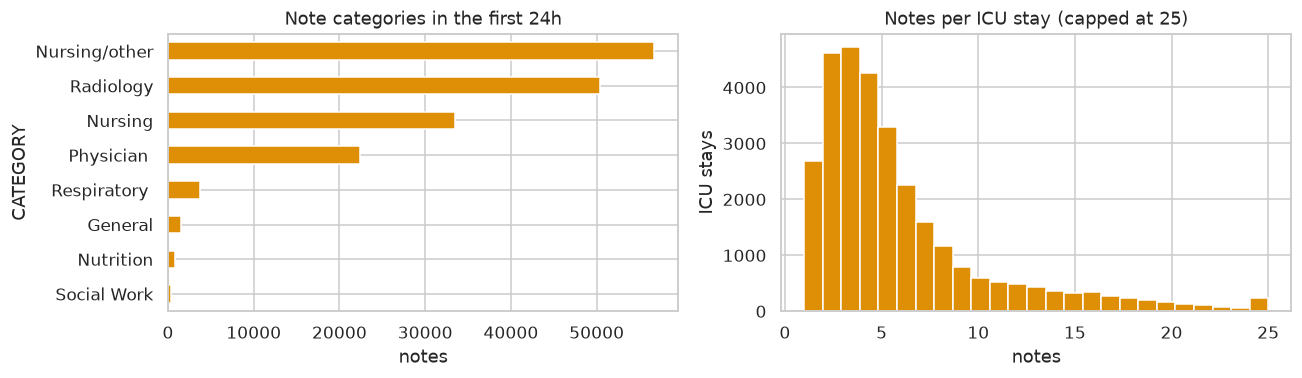

      n_notes  n_words
mean      6.0   1560.0
50%       4.0    707.0
max      50.0  35354.0


In [4]:
per_stay = notes.groupby("HADM_ID").agg(n_notes=("TEXT", "size"), n_words=("TEXT", lambda s: s.str.split().str.len().sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
notes["CATEGORY"].value_counts().head(8).sort_values().plot.barh(ax=axes[0], color=COLORS["notes"])
axes[0].set(title="Note categories in the first 24h", xlabel="notes")
axes[1].hist(per_stay["n_notes"].clip(upper=25), bins=25, color=COLORS["notes"])
axes[1].set(title="Notes per ICU stay (capped at 25)", xlabel="notes", ylabel="ICU stays")
plt.tight_layout()
savefig("notes_overview")
print(per_stay.describe().loc[["mean", "50%", "max"]].round(0).to_string())

## 3. Structured features: vitals and labs

The ITEMIDs come from the MIMIC code repository (`first_day_vitals` and `first_day_labs`). There are
two ITEMIDs for most things because MIMIC-III has data from two systems, CareVue (older) and
MetaVision (newer). I also drop impossible values, like a heart rate of 600, using the same ranges
as the MIMIC code repo.

`CHARTEVENTS` has 330 million rows, so this is the slow part (~15 min). I only load four columns and
filter each chunk right away.

In [5]:
VITALS = {   # name: ([itemids], (low, high))
    "heart_rate": ([211, 220045], (0, 300)),
    "sbp":        ([51, 442, 455, 6701, 220179, 220050], (0, 400)),
    "dbp":        ([8368, 8440, 8441, 8555, 220180, 220051], (0, 300)),
    "mbp":        ([456, 52, 6702, 443, 220052, 220181, 225312], (0, 300)),
    "resp_rate":  ([615, 618, 220210, 224690], (0, 70)),
    "temp_c":     ([223762, 676, 223761, 678], (10, 50)),
    "spo2":       ([646, 220277], (0, 100)),
    "glucose":    ([807, 811, 1529, 3745, 3744, 225664, 220621, 226537], (0, 2000)),
    "gcs_eyes":   ([184, 220739], (0, 4)),
    "gcs_motor":  ([454, 223901], (0, 6)),
    "gcs_verbal": ([723, 223900], (0, 5)),
}
FAHRENHEIT = {223761, 678}
item2vital = {i: name for name, (ids, _) in VITALS.items() for i in ids}

vitals_path = CACHE / "vitals_24h.parquet"
if vitals_path.exists():
    ce = pd.read_parquet(vitals_path)
else:
    t0 = time.time()
    intime = df.set_index("ICUSTAY_ID")["INTIME"]
    keep = []
    for ch in pd.read_csv(DATA_DIR / "CHARTEVENTS.csv.gz", chunksize=5_000_000,
                          usecols=["ICUSTAY_ID", "ITEMID", "CHARTTIME", "VALUENUM", "ERROR"]):
        ch = ch[ch["ITEMID"].isin(item2vital.keys()) & ch["ICUSTAY_ID"].isin(intime.index)
                & ch["VALUENUM"].notna() & (ch["ERROR"] != 1)]
        hours = (pd.to_datetime(ch["CHARTTIME"]) - ch["ICUSTAY_ID"].map(intime)).dt.total_seconds() / 3600
        keep.append(ch[(hours >= 0) & (hours < 24)][["ICUSTAY_ID", "ITEMID", "VALUENUM"]])
    ce = pd.concat(keep)
    ce.to_parquet(vitals_path)
    print(f"read CHARTEVENTS in {(time.time() - t0) / 60:.1f} min")

ce["name"] = ce["ITEMID"].map(item2vital)
f = ce["ITEMID"].isin(FAHRENHEIT)
ce.loc[f, "VALUENUM"] = (ce.loc[f, "VALUENUM"] - 32) / 1.8      # Fahrenheit -> Celsius
lo = ce["name"].map(lambda n: VITALS[n][1][0]); hi = ce["name"].map(lambda n: VITALS[n][1][1])
ce = ce[(ce["VALUENUM"] > lo) & (ce["VALUENUM"] <= hi)]
print(f"{len(ce):,} vital sign measurements")

# one row per ICU stay: min / max / mean of each vital (only the worst value for GCS)
vit = ce.pivot_table(index="ICUSTAY_ID", columns="name", values="VALUENUM", aggfunc=["min", "max", "mean"])
vit.columns = [f"{name}_{agg}" for agg, name in vit.columns]
vit = vit[[c for c in vit.columns if not (c.startswith("gcs") and not c.endswith("_min"))]]
vit.shape

7,021,442 vital sign measurements


(29737, 27)

In [6]:
LABS = {   # name: ([itemids], upper limit)
    "anion_gap": ([50868], 10000), "albumin": ([50862], 10), "bicarbonate": ([50882], 10000),
    "bilirubin": ([50885], 150), "creatinine": ([50912], 150), "chloride": ([50902, 50806], 10000),
    "glucose_lab": ([50931, 50809], 10000), "hematocrit": ([51221, 50810], 100), "hemoglobin": ([51222, 50811], 50),
    "lactate": ([50813], 50), "platelets": ([51265], 10000), "potassium": ([50971, 50822], 30),
    "ptt": ([51275], 150), "inr": ([51237], 50), "sodium": ([50983, 50824], 200), "bun": ([51006], 300),
    "wbc": ([51301, 51300], 1000),
}
item2lab = {i: name for name, (ids, _) in LABS.items() for i in ids}

# labs are linked by HADM_ID, and I allow 6h before ICU admission since a lot of labs are drawn in the ED
intime = df.set_index("HADM_ID")["INTIME"]
keep = []
for ch in pd.read_csv(DATA_DIR / "LABEVENTS.csv.gz", chunksize=5_000_000, usecols=["HADM_ID", "ITEMID", "CHARTTIME", "VALUENUM"]):
    ch = ch[ch["ITEMID"].isin(item2lab.keys()) & ch["HADM_ID"].isin(intime.index) & ch["VALUENUM"].notna()]
    hours = (pd.to_datetime(ch["CHARTTIME"]) - ch["HADM_ID"].map(intime)).dt.total_seconds() / 3600
    keep.append(ch[(hours >= -6) & (hours < 24)])
le = pd.concat(keep)
le["name"] = le["ITEMID"].map(item2lab)
le = le[(le["VALUENUM"] > 0) & (le["VALUENUM"] <= le["name"].map(lambda n: LABS[n][1]))]
print(f"{len(le):,} lab results")

lab = le.pivot_table(index="HADM_ID", columns="name", values="VALUENUM", aggfunc=["min", "max"])
lab.columns = [f"{name}_{agg}" for agg, name in lab.columns]
lab.shape

1,397,232 lab results


(29768, 34)

Now I put everything into one table with one row per ICU stay. Age, gender, admission type and the
first ICU unit go in as well. Missing values stay as `NaN` for now, since each model handles them a
bit differently.

(29901, 69) | deaths: 3124


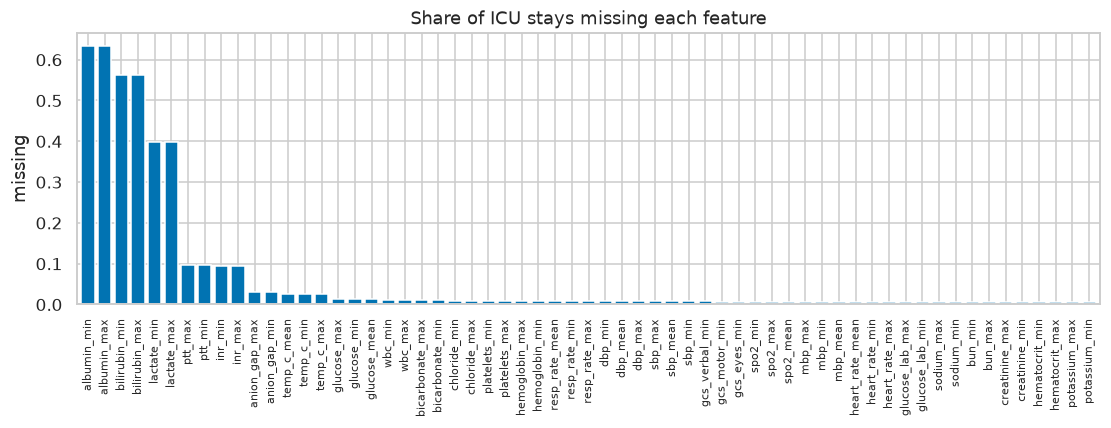

In [7]:
demo = pd.DataFrame({
    "age": df["AGE"].values,
    "male": (df["GENDER"] == "M").astype(int).values,
    "emergency": df["ADMISSION_TYPE"].isin(["EMERGENCY", "URGENT"]).astype(int).values,
}, index=df["ICUSTAY_ID"])
units = pd.get_dummies(df.set_index("ICUSTAY_ID")["FIRST_CAREUNIT"], prefix="unit", dtype=int)

X_struct = demo.join(units).join(vit)
X_struct["HADM_ID"] = df["HADM_ID"].values
X_struct = X_struct.join(lab, on="HADM_ID").drop(columns="HADM_ID").reset_index(drop=True)
y = df["HOSPITAL_EXPIRE_FLAG"].values
print(X_struct.shape, "| deaths:", y.sum())

miss = X_struct.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 3.2))
miss[miss > 0].plot.bar(ax=ax, color=COLORS["structured"], width=.8)
ax.set(title="Share of ICU stays missing each feature", ylabel="missing")
ax.tick_params(axis="x", labelsize=7)
savefig("missingness")

## 4. Train / validation / test split

70 / 15 / 15, stratified on the outcome so all three sets have the same ~11% mortality. The
validation set is only used for picking hyperparameters and fusion weights. The test set is not
touched until the final results in section 8.

In [8]:
idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)
for name, s in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5s} {len(s):6,} stays   mortality {y[s].mean():.1%}")

preds = {}   # model name -> predicted probabilities for every stay in val and test

def report(name, p):
    preds[name] = p
    print(f"{name:28s} val AUROC {roc_auc_score(y[va], p[va]):.3f}   AUPRC {average_precision_score(y[va], p[va]):.3f}")

train 20,930 stays   mortality 10.4%
val    4,485 stays   mortality 10.4%
test   4,486 stays   mortality 10.5%


## 5. Structured-only models

Two baselines:

* **Logistic regression**: needs no missing values, so I fill with the training median, add a
  "was missing" flag for each column, and standardise.
* **Gradient boosting** (`HistGradientBoostingClassifier`): handles `NaN` by itself and picks up
  non-linear stuff like "both low and high temperature are bad".

In [9]:
pre_struct = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())
Xs = pre_struct.fit(X_struct.iloc[tr]).transform(X_struct)   # fitted on train only, applied to everyone

lr_struct = LogisticRegression(C=0.1, max_iter=5000).fit(Xs[tr], y[tr])
report("Structured LR", lr_struct.predict_proba(Xs)[:, 1])

gb_struct = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=600, early_stopping=True,
                                           validation_fraction=0.1, random_state=SEED).fit(X_struct.iloc[tr], y[tr])
report("Structured GBM", gb_struct.predict_proba(X_struct)[:, 1])

Structured LR                val AUROC 0.868   AUPRC 0.483


Structured GBM               val AUROC 0.890   AUPRC 0.525


## 6. Notes-only models

First I join all the first-24h notes of each stay into one document (in time order).

**TF-IDF + logistic regression.** This is the classic bag-of-words baseline. `min_df=20` drops
any word that appears in fewer than 20 stays, which also gets rid of typos and rare tokens. I pick
the regularisation strength `C` on the validation set.

In [10]:
docs = notes.groupby("HADM_ID")["TEXT"].apply(" ".join).loc[df["HADM_ID"]].values

tfidf = TfidfVectorizer(min_df=20, max_df=0.9, ngram_range=(1, 2), max_features=50_000,
                        sublinear_tf=True, stop_words="english")
T_tr = tfidf.fit_transform(docs[tr])            # vocabulary learned from train only
T_all = tfidf.transform(docs)
print("vocabulary size:", len(tfidf.vocabulary_))

for C in [0.3, 1, 3]:
    m = LogisticRegression(C=C, max_iter=5000).fit(T_tr, y[tr])
    print(f"C={C:<4} val AUROC {roc_auc_score(y[va], m.predict_proba(T_all[va])[:, 1]):.3f}")

vocabulary size: 50000


C=0.3  val AUROC 0.870


C=1    val AUROC 0.879


C=3    val AUROC 0.881


In [11]:
lr_tfidf = LogisticRegression(C=1, max_iter=5000).fit(T_tr, y[tr])
report("Notes TF-IDF LR", lr_tfidf.predict_proba(T_all)[:, 1])

Notes TF-IDF LR              val AUROC 0.879   AUPRC 0.533


**ClinicalBERT embeddings.** Bio_ClinicalBERT is BERT that was further trained on MIMIC notes, so
it already knows clinical language. I don't fine-tune it here, I only use it as a feature extractor:

1. tokenise each stay's document
2. split it into 510-token pieces (BERT's limit is 512 including the `[CLS]` and `[SEP]` tokens),
   and keep the first 4 pieces per stay (the earliest ~2,000 tokens, to keep it fast)
3. run each piece through BERT and average the last hidden layer over its tokens (mean pooling)
4. average the pieces, so every ICU stay ends up as one 768-number vector

This needs a GPU (a few minutes). The result is cached in `cache/`.

In [12]:
from transformers import AutoTokenizer, AutoModel
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()          # hides the "sequence longer than 512" warning, we chunk anyway

BERT = "emilyalsentzer/Bio_ClinicalBERT"
CHUNK, MAX_CHUNKS = 510, 4
emb_path = CACHE / "clinicalbert_emb.npy"

if emb_path.exists():
    E = np.load(emb_path)
else:
    tok = AutoTokenizer.from_pretrained(BERT)
    bert = AutoModel.from_pretrained(BERT).to(DEVICE).eval().half()

    # cut every document into chunks of token ids
    chunks, owner = [], []
    for i in range(0, len(docs), 1000):
        ids = tok(list(docs[i:i + 1000]), add_special_tokens=False)["input_ids"]
        for j, seq in enumerate(ids):
            for k in range(0, min(len(seq), CHUNK * MAX_CHUNKS), CHUNK):
                chunks.append([tok.cls_token_id] + seq[k:k + CHUNK] + [tok.sep_token_id])
                owner.append(i + j)
    owner = np.array(owner)
    print(f"{len(chunks):,} chunks for {len(docs):,} stays")

    # sort by length so each batch needs little padding
    order = np.argsort([len(c) for c in chunks])
    sums, counts = np.zeros((len(docs), 768), dtype=np.float32), np.bincount(owner, minlength=len(docs))
    t0 = time.time()
    with torch.no_grad():
        for b in range(0, len(order), 32):
            batch = [chunks[k] for k in order[b:b + 32]]
            L = max(map(len, batch))
            ids = torch.tensor([c + [0] * (L - len(c)) for c in batch], device=DEVICE)
            mask = (ids != 0).half()
            hidden = bert(input_ids=ids, attention_mask=mask).last_hidden_state
            pooled = (hidden * mask[..., None]).sum(1) / mask.sum(1, keepdim=True)   # mean over real tokens
            np.add.at(sums, owner[order[b:b + 32]], pooled.float().cpu().numpy())
    E = sums / counts[:, None]
    np.save(emb_path, E)
    print(f"embedded in {(time.time() - t0) / 60:.1f} min")
E.shape

92,604 chunks for 29,901 stays


embedded in 2.7 min


(29901, 768)

In [13]:
scale_E = StandardScaler().fit(E[tr])
Es = scale_E.transform(E)

for C in [0.01, 0.03, 0.1]:
    m = LogisticRegression(C=C, max_iter=5000).fit(Es[tr], y[tr])
    print(f"C={C:<5} val AUROC {roc_auc_score(y[va], m.predict_proba(Es[va])[:, 1]):.3f}")

C=0.01  val AUROC 0.821


C=0.03  val AUROC 0.821


C=0.1   val AUROC 0.816


In [14]:
lr_bert = LogisticRegression(C=0.01, max_iter=5000).fit(Es[tr], y[tr])
report("Notes ClinicalBERT LR", lr_bert.predict_proba(Es)[:, 1])

Notes ClinicalBERT LR        val AUROC 0.821   AUPRC 0.379


## 7. Fusion

This is the main part. There are three common ways to combine two kinds of data:

| | how | here |
|---|---|---|
| **early fusion** | join the features into one big input, train one model | structured features + ClinicalBERT vector (PCA to 64 dims) into gradient boosting |
| **late fusion** | train a model per modality, then combine their predictions | weighted average of the structured GBM and the notes model, weight picked on validation |
| **intermediate fusion** | a neural net with one branch per modality, joined in the middle and trained together | two-branch PyTorch MLP |

In [15]:
# early fusion: 768 BERT dims would swamp ~90 structured columns, so I shrink them to 64 with PCA first
pca = PCA(n_components=64, random_state=SEED).fit(Es[tr])
print(f"64 PCA components keep {pca.explained_variance_ratio_.sum():.0%} of the embedding variance")
X_early = np.hstack([X_struct.values, pca.transform(Es)])

gb_early = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=600, early_stopping=True,
                                          validation_fraction=0.1, random_state=SEED).fit(X_early[tr], y[tr])
report("Early fusion GBM", gb_early.predict_proba(X_early)[:, 1])

64 PCA components keep 92% of the embedding variance


Early fusion GBM             val AUROC 0.889   AUPRC 0.543


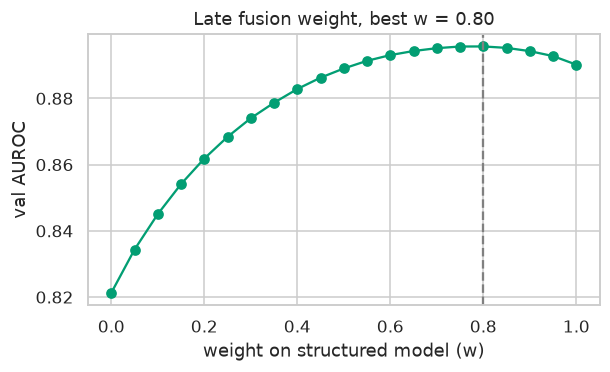

Late fusion (avg)            val AUROC 0.896   AUPRC 0.540


In [16]:
# late fusion: p = w * structured + (1 - w) * notes, try w from 0 to 1 on the validation set
p_s, p_n = preds["Structured GBM"], preds["Notes ClinicalBERT LR"]
ws = np.linspace(0, 1, 21)
val_auc = [roc_auc_score(y[va], w * p_s[va] + (1 - w) * p_n[va]) for w in ws]
best_w = ws[int(np.argmax(val_auc))]

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ws, val_auc, marker="o", color=COLORS["fusion"])
ax.axvline(best_w, ls="--", color="grey")
ax.set(xlabel="weight on structured model (w)", ylabel="val AUROC", title=f"Late fusion weight, best w = {best_w:.2f}")
savefig("late_fusion_weight")
report("Late fusion (avg)", best_w * p_s + (1 - best_w) * p_n)

For intermediate fusion, each modality gets its own small network that squeezes it down to 64
numbers. The two are concatenated and a final layer makes the prediction. Since everything is
trained together, the net can learn how the two inputs interact. I stop training once validation
AUROC hasn't improved for 5 epochs and keep the best epoch.

In [17]:
class FusionNet(torch.nn.Module):
    def __init__(self, d_struct, d_text, hidden=64, drop=0.3):
        super().__init__()
        branch = lambda d: torch.nn.Sequential(torch.nn.Linear(d, 128), torch.nn.ReLU(), torch.nn.Dropout(drop),
                                               torch.nn.Linear(128, hidden), torch.nn.ReLU())
        self.struct, self.text = branch(d_struct), branch(d_text)
        self.head = torch.nn.Sequential(torch.nn.Dropout(drop), torch.nn.Linear(2 * hidden, 1))

    def forward(self, xs, xt):
        return self.head(torch.cat([self.struct(xs), self.text(xt)], dim=1)).squeeze(1)

def to_t(a):
    return torch.tensor(a, dtype=torch.float32, device=DEVICE)

XS, XT, Y = to_t(Xs), to_t(Es), to_t(y)
net = FusionNet(Xs.shape[1], Es.shape[1]).to(DEVICE)
opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-3)
loss_fn = torch.nn.BCEWithLogitsLoss()

history, best, best_state, wait = [], 0, None, 0
for epoch in range(100):
    net.train()
    for b in np.array_split(np.random.permutation(tr), len(tr) // 256):
        opt.zero_grad()
        loss = loss_fn(net(XS[b], XT[b]), Y[b])
        loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        auc = roc_auc_score(y[va], torch.sigmoid(net(XS[va], XT[va])).cpu().numpy())
    history.append((loss.item(), auc))
    if auc > best:
        best, best_state, wait = auc, {k: v.clone() for k, v in net.state_dict().items()}, 0
    else:
        wait += 1
        if wait == 5:
            break
net.load_state_dict(best_state); net.eval()
print(f"stopped after {epoch + 1} epochs, best val AUROC {best:.3f} at epoch {int(np.argmax([h[1] for h in history])) + 1}")

with torch.no_grad():
    report("Intermediate fusion (NN)", torch.sigmoid(net(XS, XT)).cpu().numpy())

stopped after 14 epochs, best val AUROC 0.891 at epoch 9
Intermediate fusion (NN)     val AUROC 0.891   AUPRC 0.554


## 8. Test set results

Now the test set, which none of the choices above have seen. Along with AUROC I report AUPRC, which
is more informative when only ~11% of patients die, and the Brier score (lower is better, it checks
whether the probabilities are well calibrated). The 95% intervals come from 1,000 bootstrap
resamples of the test set.

In [18]:
rng = np.random.default_rng(SEED)
boot = [rng.choice(te, len(te)) for _ in range(1000)]
boot = [b for b in boot if y[b].any()]

rows = []
for name, p in preds.items():
    aucs = [roc_auc_score(y[b], p[b]) for b in boot]
    rows.append({"model": name,
                 "AUROC": roc_auc_score(y[te], p[te]),
                 "95% CI": f"{np.percentile(aucs, 2.5):.3f} - {np.percentile(aucs, 97.5):.3f}",
                 "AUPRC": average_precision_score(y[te], p[te]),
                 "Brier": brier_score_loss(y[te], p[te])})
results = pd.DataFrame(rows).set_index("model").round(3)
results.to_csv(FIG_DIR / "results.csv")
results

,AUROC,95% CI,AUPRC,Brier
model,,,,
Structured LR,0.854,0.838 - 0.871,0.439,0.074
Structured GBM,0.879,0.866 - 0.893,0.480,0.070
Notes TF-IDF LR,0.875,0.860 - 0.889,0.502,0.071
Notes ClinicalBERT LR,0.824,0.803 - 0.842,0.384,0.078
Early fusion GBM,0.882,0.867 - 0.896,0.505,0.069
Late fusion (avg),0.888,0.875 - 0.902,0.503,0.069
Intermediate fusion (NN),0.883,0.869 - 0.897,0.496,0.070


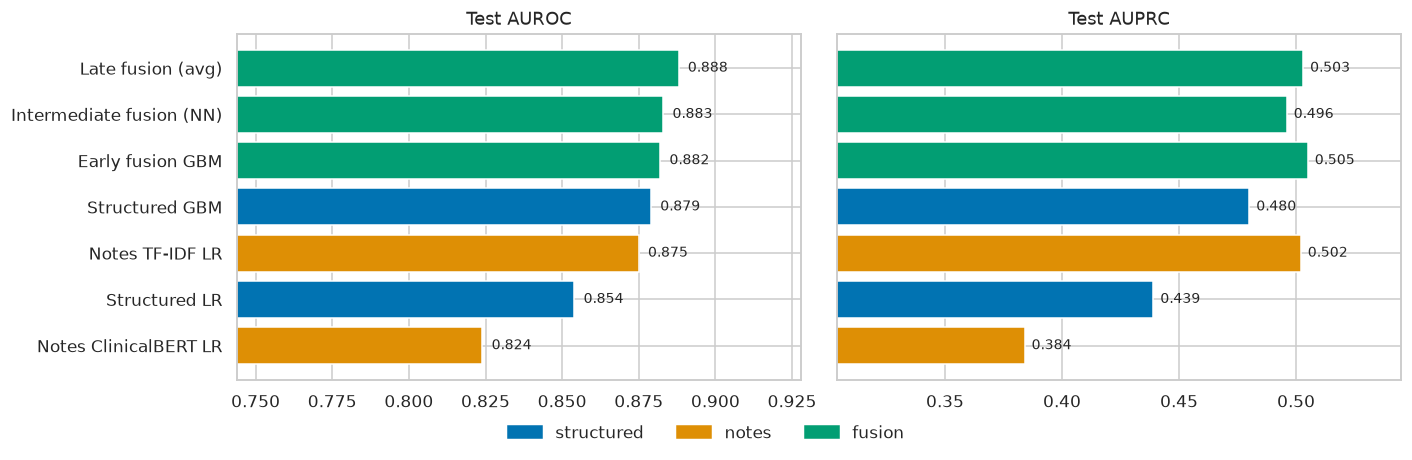

In [19]:
kind = lambda n: "structured" if n.startswith("Structured") else "notes" if n.startswith("Notes") else "fusion"
order = results.sort_values("AUROC").index

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["AUROC", "AUPRC"]):
    vals = results.loc[order, metric]
    ax.barh(order, vals, color=[COLORS[kind(n)] for n in order])
    for i, v in enumerate(vals):
        ax.text(v + .003, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set(xlim=(vals.min() - .08, vals.max() + .04), title=f"Test {metric}")
axes[1].set_yticklabels([])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()]
fig.legend(handles, COLORS.keys(), loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, -.06))
plt.tight_layout()
savefig("test_bars")

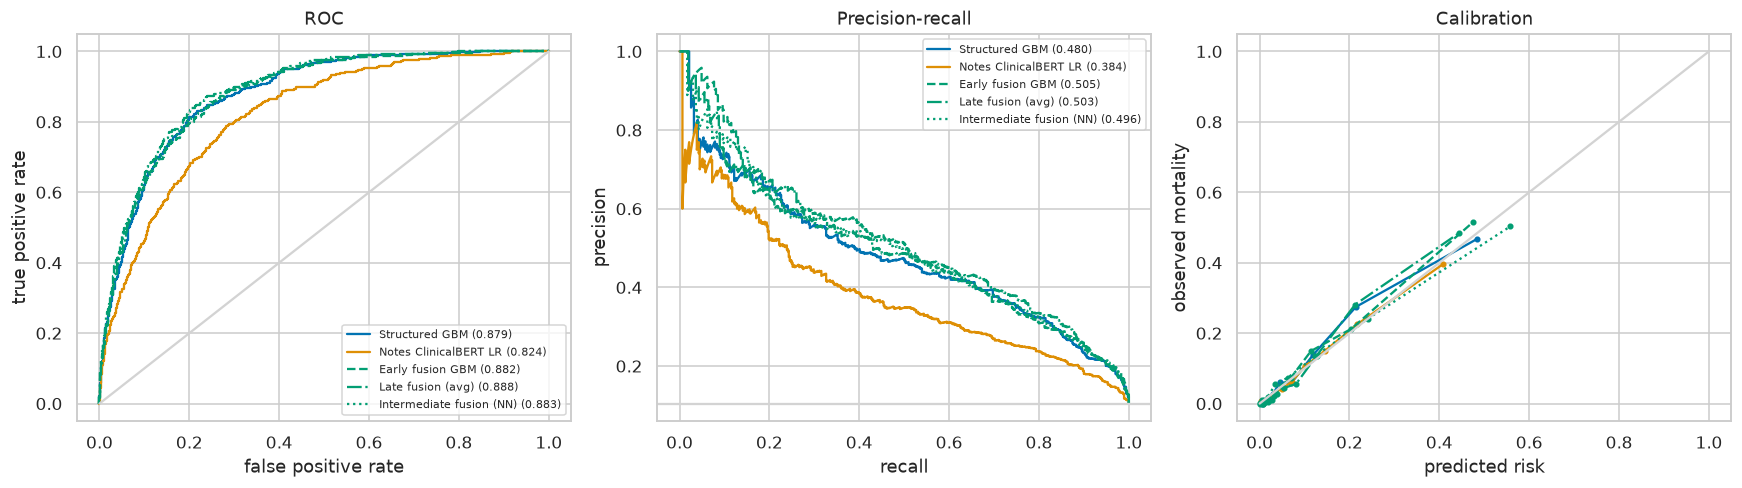

In [20]:
show = ["Structured GBM", "Notes ClinicalBERT LR", "Early fusion GBM", "Late fusion (avg)", "Intermediate fusion (NN)"]
lines = ["-", "-", "--", "-.", ":"]
col = lambda n: COLORS[kind(n)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for n, ls in zip(show, lines):
    fpr, tpr, _ = roc_curve(y[te], preds[n][te])
    axes[0].plot(fpr, tpr, ls=ls, color=col(n), label=f"{n} ({results.loc[n, 'AUROC']:.3f})")
    prec, rec, _ = precision_recall_curve(y[te], preds[n][te])
    axes[1].plot(rec, prec, ls=ls, color=col(n), label=f"{n} ({results.loc[n, 'AUPRC']:.3f})")
    frac, mean_p = calibration_curve(y[te], preds[n][te], n_bins=10, strategy="quantile")
    axes[2].plot(mean_p, frac, ls=ls, marker="o", ms=3, color=col(n), label=n)
axes[0].plot([0, 1], [0, 1], color="lightgrey"); axes[2].plot([0, 1], [0, 1], color="lightgrey")
axes[1].axhline(y[te].mean(), color="lightgrey")
axes[0].set(title="ROC", xlabel="false positive rate", ylabel="true positive rate")
axes[1].set(title="Precision-recall", xlabel="recall", ylabel="precision")
axes[2].set(title="Calibration", xlabel="predicted risk", ylabel="observed mortality")
for ax in axes[:2]:
    ax.legend(fontsize=7.5, loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout()
savefig("test_curves")

Is the gain from fusion real, or just noise? I bootstrap the **difference** in AUROC between the
best fusion model and the structured GBM on the same resamples (paired bootstrap). If the 95%
interval doesn't include 0, the improvement is unlikely to be luck.

In [21]:
best_fusion = results.loc[[n for n in results.index if kind(n) == "fusion"], "AUROC"].idxmax()
diff = [roc_auc_score(y[b], preds[best_fusion][b]) - roc_auc_score(y[b], preds["Structured GBM"][b]) for b in boot]
lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"{best_fusion} minus Structured GBM: AUROC +{np.mean(diff):.3f}  (95% CI {lo:+.3f} to {hi:+.3f})")
print(f"fusion better in {np.mean(np.array(diff) > 0):.1%} of bootstrap samples")

Late fusion (avg) minus Structured GBM: AUROC +0.009  (95% CI +0.006 to +0.013)
fusion better in 100.0% of bootstrap samples


## 9. What are the models looking at?

**Structured GBM: permutation importance.** I shuffle one feature at a time on the validation set and
see how much the AUROC drops. A big drop means the model relies on that feature.

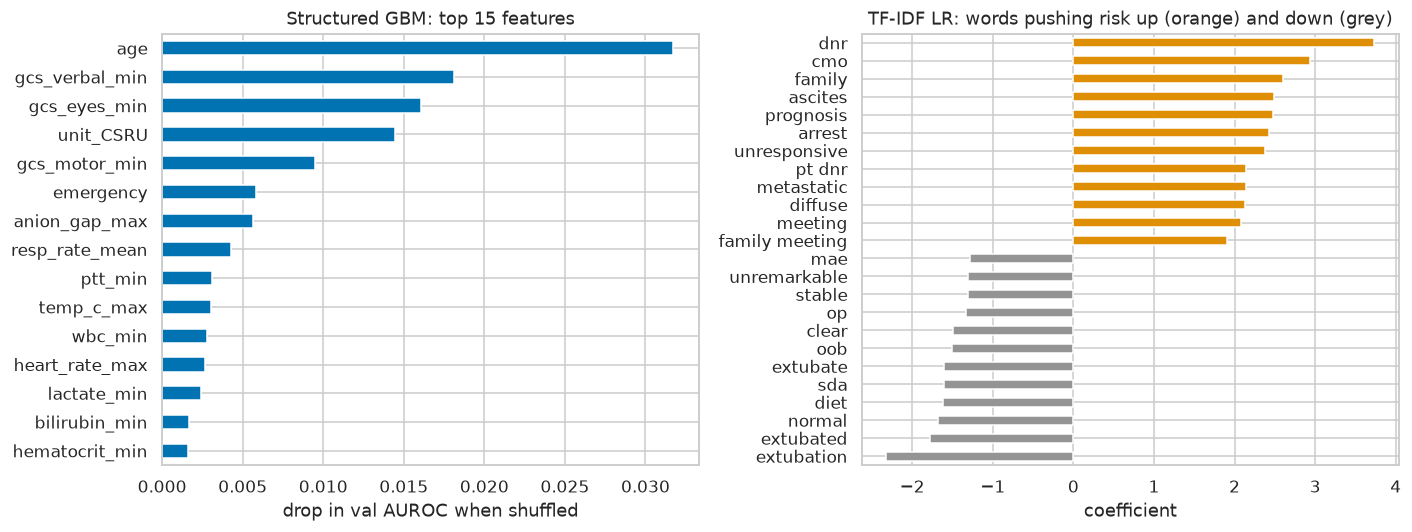

In [22]:
pi = permutation_importance(gb_struct, X_struct.iloc[va], y[va], scoring="roc_auc", n_repeats=5, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X_struct.columns).sort_values().tail(15)

# TF-IDF model: biggest positive and negative coefficients
coef = pd.Series(lr_tfidf.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
coef = coef[coef.index.str.fullmatch(r"[a-z ]+")]      # skip tokens like "____" from form lines
words = pd.concat([coef.head(12), coef.tail(12)])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
imp.plot.barh(ax=axes[0], color=COLORS["structured"])
axes[0].set(title="Structured GBM: top 15 features", xlabel="drop in val AUROC when shuffled")
words.plot.barh(ax=axes[1], color=[COLORS["notes"] if v > 0 else "#949494" for v in words])
axes[1].set(title="TF-IDF LR: words pushing risk up (orange) and down (grey)", xlabel="coefficient")
plt.tight_layout()
savefig("interpretation")

**Where do the notes help most?** AUROC per first ICU unit for the structured GBM vs. the best fusion
model, on the test set.

,n,deaths,Structured GBM,Late fusion (avg)
unit,,,,
MICU,1531,223,0.844,0.852
CSRU,972,29,0.901,0.917
SICU,722,94,0.880,0.887
TSICU,636,58,0.853,0.872
CCU,625,65,0.880,0.897


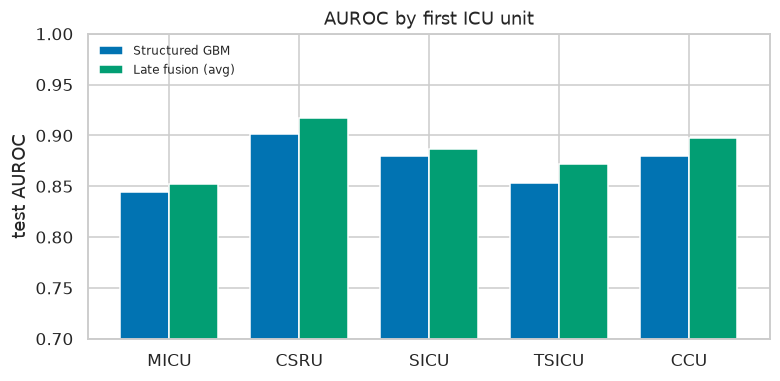

In [23]:
unit_te = df["FIRST_CAREUNIT"].values[te]
rows = []
for u in pd.Series(unit_te).value_counts().index:
    m = unit_te == u
    rows.append({"unit": u, "n": m.sum(), "deaths": y[te][m].sum(),
                 "Structured GBM": roc_auc_score(y[te][m], preds["Structured GBM"][te][m]),
                 best_fusion: roc_auc_score(y[te][m], preds[best_fusion][te][m])})
by_unit = pd.DataFrame(rows).set_index("unit").round(3)
display(by_unit)

ax = by_unit[["Structured GBM", best_fusion]].plot.bar(figsize=(8, 3.6), color=[COLORS["structured"], COLORS["fusion"]], rot=0, width=.75)
ax.set(ylim=(.7, 1), ylabel="test AUROC", title="AUROC by first ICU unit", xlabel="")
ax.legend(loc="upper left", fontsize=8, frameon=False)
savefig("by_unit")

## 10. Wrap-up

* **Structured only:** gradient boosting (test AUROC 0.879) beats logistic regression (0.854).
* **Notes only:** TF-IDF (0.875) is almost as good as the vitals and labs, which surprised me. Frozen
  ClinicalBERT with mean pooling only got 0.824. My guess is that averaging hundreds of token vectors
  washes out the details, and I only used the first ~2,000 tokens per stay.
* **Fusion:** all three fusion models beat the structured GBM. Late fusion was the best (0.888) and is
  also the simplest. The paired bootstrap says the +0.009 gain is small but real (95% CI +0.006 to
  +0.013). The notes helped most in the CSRU, TSICU and CCU.

Limitations: one hospital (Beth Israel), one train/test split, and stays without any notes in the
first 24h were dropped. Also, some notes probably mention things like comfort care or DNR status,
which are real information at hour 24 but are partly a decision rather than a physiology signal.

Things to try next: fuse the TF-IDF model instead of ClinicalBERT (it was the stronger notes model),
or fine-tune ClinicalBERT end-to-end instead of freezing it.